In [182]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
import numpy as np
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

Using device: cuda


In [183]:
class Encoder(nn.Module):
  def __init__(self):
    super().__init__()
    self.feature_extractor = nn.Sequential(
      nn.Conv2d(1, 32, 4, stride=2, padding=1),
      nn.ReLU(),
      nn.Conv2d(32, 64, 4, stride=2, padding=1),
      nn.ReLU(),
      nn.Conv2d(64, 128, 3, stride=1, padding=0),
      nn.ReLU()
    )
    self.fc = nn.Linear(128 * 5 * 5, 32)

  def forward(self, x):
    x = self.feature_extractor(x)
    x = x.view(x.size(0), -1)
    return self.fc(x)

device = "cuda" if torch.cuda.is_available() else "cpu"

svdd = Encoder().to(device)
svdd.load_state_dict(torch.load("mnist_svdd.pth", map_location=device))
c = torch.tensor(np.load("center.npy"), device=device)
best_thresh = float(np.load("threshold.npy"))

/tmp/ipython-input-3640739520.py:24: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  best_thresh = float(np.load("threshold.npy"))


In [184]:
GITHUB_LINK = 'https://github.com/csinva/gan-vae-pretrained-pytorch/tree/master'

In [185]:
class Generator(nn.Module):
    def __init__(self, ngpu, nc=1, nz=100, ngf=64):
        super(Generator, self).__init__()
        self.ngpu = ngpu
        self.main = nn.Sequential(
            # input is Z, going into a convolution
            nn.ConvTranspose2d(     nz, ngf * 8, 4, 1, 0, bias=False),
            nn.BatchNorm2d(ngf * 8),
            nn.ReLU(True),
            # state size. (ngf*8) x 4 x 4
            nn.ConvTranspose2d(ngf * 8, ngf * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ngf * 4),
            nn.ReLU(True),
            # state size. (ngf*4) x 8 x 8
            nn.ConvTranspose2d(ngf * 4, ngf * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ngf * 2),
            nn.ReLU(True),
            # state size. (ngf*2) x 16 x 16
            nn.ConvTranspose2d(ngf * 2,     ngf, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ngf),
            nn.ReLU(True),
            nn.ConvTranspose2d(    ngf,      nc, kernel_size=1, stride=1, padding=2, bias=False),
            nn.Tanh()
        )

    def forward(self, input):
        if input.is_cuda and self.ngpu > 1:
            output = nn.parallel.data_parallel(self.main, input, range(self.ngpu))
        else:
            output = self.main(input)
        return output


class Discriminator(nn.Module):
    def __init__(self, ngpu, nc=1, ndf=64):
        super(Discriminator, self).__init__()
        self.ngpu = ngpu
        self.main = nn.Sequential(
            # input is (nc) x 64 x 64
            nn.Conv2d(nc, ndf, 4, 2, 1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),
            # state size. (ndf) x 32 x 32
            nn.Conv2d(ndf, ndf * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ndf * 2),
            nn.LeakyReLU(0.2, inplace=True),
            # state size. (ndf*2) x 16 x 16
            nn.Conv2d(ndf * 2, ndf * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ndf * 4),
            nn.LeakyReLU(0.2, inplace=True),
            # state size. (ndf*4) x 8 x 8
            nn.Conv2d(ndf * 4, 1, 4, 2, 1, bias=False),
            nn.Sigmoid()
        )

    def forward(self, input):
        if input.is_cuda and self.ngpu > 1:
            output = nn.parallel.data_parallel(self.main, input, range(self.ngpu))
        else:
            output = self.main(input)
        return output.view(-1, 1).squeeze(1)

In [186]:
# loading weights for both generator and discriminator
!wget https://github.com/csinva/gan-vae-pretrained-pytorch/raw/master/mnist_dcgan/weights/netG_epoch_99.pth -O netG.pth
!wget https://github.com/csinva/gan-vae-pretrained-pytorch/raw/master/mnist_dcgan/weights/netD_epoch_99.pth -O netD.pth

--2025-11-24 17:57:09--  https://github.com/csinva/gan-vae-pretrained-pytorch/raw/master/mnist_dcgan/weights/netG_epoch_99.pth
Resolving github.com (github.com)... 140.82.114.4
Connecting to github.com (github.com)|140.82.114.4|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://raw.githubusercontent.com/csinva/gan-vae-pretrained-pytorch/master/mnist_dcgan/weights/netG_epoch_99.pth [following]
--2025-11-24 17:57:09--  https://raw.githubusercontent.com/csinva/gan-vae-pretrained-pytorch/master/mnist_dcgan/weights/netG_epoch_99.pth
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 14306386 (14M) [application/octet-stream]
Saving to: ‘netG.pth’

netG.pth            100%[===================>]  13.64M  --.-KB/s    in 0.03s   

2025

=== Sanity check: classifier + GAN integration ===
svdd type: <class '__main__.Encoder'>
Generator type: <class '__main__.Generator'>
c shape: torch.Size([32])
best_thresh: -6.921492968103848e-06
fake shape from netG: torch.Size([64, 1, 28, 28])
features shape from svdd: torch.Size([64, 32])
distances shape: torch.Size([64])
distances (first 5): [0.00208139 0.00228841 0.00327704 0.00370244 0.00206821]
Detected ZERO cluster: 0
Detected ZERO cluster: 0
Showing 16 samples from cluster 0


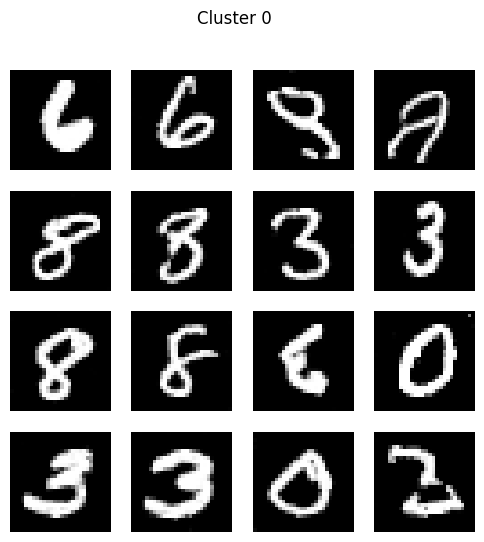

Mean distance of cluster: 0.0019799925
Std distance: 0.00021240315
Real MNIST 0 mean: 4.79147684018244e-06


In [187]:
ngpu = 1
device = "cuda"

netG = Generator(ngpu=ngpu, nc=1, nz=100, ngf=64).to(device)
netD = Discriminator(ngpu=ngpu, nc=1, ndf=64).to(device)

G_state = torch.load("netG.pth", map_location=device)
D_state = torch.load("netD.pth", map_location=device)

netG.load_state_dict(G_state)
netD.load_state_dict(D_state)

import torch

print("svdd type:", type(svdd))
print("Generator type:", type(netG))

print("c shape:", c.shape)
print("best_thresh:", best_thresh)

svdd.eval()
netG.eval()

with torch.no_grad():
    z = torch.randn(64, 100, 1, 1, device=device)
    fake = netG(z)

print("fake shape from netG:", fake.shape)

with torch.no_grad():
    feats = svdd(fake)
    dist  = torch.sum((feats - c)**2, dim=1)

print("features shape from svdd:", feats.shape)
print("distances shape:", dist.shape)
print("distances (first 5):", dist[:5].cpu().numpy())

ngpu = 1
device = "cuda"

netG = Generator(ngpu=ngpu, nc=1, nz=100, ngf=64).to(device)
netD = Discriminator(ngpu=ngpu, nc=1, ndf=64).to(device)

G_state = torch.load("netG.pth", map_location=device)
D_state = torch.load("netD.pth", map_location=device)

netG.load_state_dict(G_state)
netD.load_state_dict(D_state)

with torch.no_grad():
    z = torch.randn(2000, 100, 1, 1).to(device)
    fake = netG(z).cpu()

def preprocess_for_svdd(x):
    x = (x + 1) / 2
    x = (x - 0.1307) / 0.3081
    return x

fake = fake.to(device)
fake_norm = preprocess_for_svdd(fake)
feats = svdd(fake_norm)
features = svdd(fake)

dist = torch.sum((features - c.to(device))**2, dim=1)

dist = dist.detach().cpu().numpy()

from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters=10, random_state=0).fit(features.detach().cpu().numpy())
clusters = kmeans.labels_

cut = np.percentile(dist, 15)
likely_zero_idx = np.where(dist < cut)[0]

cluster_counts = {}
for cid in range(10):
    cluster_counts[cid] = np.sum(clusters[likely_zero_idx] == cid)

zero_cluster = max(cluster_counts, key=cluster_counts.get)
print("Detected ZERO cluster:", zero_cluster)

import matplotlib.pyplot as plt

def show_cluster(cluster_id, fake_all, clusters, max_imgs=16):
    idxs = np.where(clusters == cluster_id)[0]

    if len(idxs) == 0:
        print(f"No images found for cluster {cluster_id}")
        return

    print(f"Showing {min(max_imgs, len(idxs))} samples from cluster {cluster_id}")

    plt.figure(figsize=(6,6))
    for i, idx in enumerate(idxs[:max_imgs]):
        plt.subplot(4,4,i+1)
        plt.imshow(fake_all[idx][0].cpu(), cmap='gray')
        plt.axis("off")
    plt.suptitle(f"Cluster {cluster_id}")
    plt.show()


print("Detected zero cluster:", zero_cluster)

show_cluster(zero_cluster, fake.cpu(), clusters)

cluster_dist = dist[likely_zero_idx]
print("Mean distance of cluster:", cluster_dist.mean())
print("Std distance:", cluster_dist.std())

from torchvision import datasets, transforms

transform = transforms.Compose([
    transforms.ToTensor(),
])

test_dataset = datasets.MNIST(root="./data", train=False, download=True, transform=transform)

real_zero_imgs = [x for (x,y) in test_dataset if y == 0][:200]
real_zero_imgs = torch.stack(real_zero_imgs).to(device)

with torch.no_grad():
    f = svdd(real_zero_imgs)
    d = torch.sum((f - c)**2, dim=1)

print("Real MNIST 0 mean:", d.mean().item())




In [188]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

class MNIST_Classifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.fc = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64*7*7, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.fc(self.conv(x))

from torchvision import datasets, transforms
from torch.utils.data import DataLoader

transform = transforms.Compose([
    transforms.ToTensor()
])

train_ds = datasets.MNIST("./data", train=True, download=True, transform=transform)
test_ds  = datasets.MNIST("./data", train=False, download=True, transform=transform)

train_loader = DataLoader(train_ds, batch_size=128, shuffle=True)
test_loader = DataLoader(test_ds, batch_size=256, shuffle=False)

clf = MNIST_Classifier().to(device)
opt = optim.Adam(clf.parameters(), lr=1e-3)

for epoch in range(3):
    clf.train()
    running = 0
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        opt.zero_grad()
        out = clf(x)
        loss = F.cross_entropy(out, y)
        loss.backward()
        opt.step()
        running += loss.item()*x.size(0)

    print(f"Epoch {epoch+1} Loss: {running/len(train_loader.dataset):.4f}")

clf.eval()
correct=0
total=0

with torch.no_grad():
    for x,y in test_loader:
        x,y = x.to(device), y.to(device)
        out = clf(x)
        pred = out.argmax(1)
        correct += (pred==y).sum().item()
        total += y.size(0)

print("Test accuracy:", correct/total)
torch.save(clf.state_dict(),"mnist_classifier.pth")

Epoch 1 Loss: 0.2349
Epoch 2 Loss: 0.0599
Epoch 3 Loss: 0.0414
Test accuracy: 0.9875


fake shape from netG: torch.Size([64, 1, 28, 28])
Predicted digits: [4 5 6 3 5 5 3 5 3 1 1 5 3 6 4 5 4 7 9 2 2 6 6 8 0 2 1 3 4 7 2 0 7 6 3 9 3
 3 2 5 6 7 2 8 4 5 1 1 4 2 0 1 9 0 7 0 1 9 2 1 3 4 3 1]
Probabilities for first 5 GAN digits:
 [[5.03753635e-14 1.91072713e-11 9.32772631e-13 5.83698090e-11
  1.00000000e+00 4.16211815e-10 1.75879710e-12 8.20879897e-09
  1.01331214e-10 1.03961701e-08]
 [1.35189097e-03 5.00006925e-10 1.06247228e-07 5.42466041e-05
  1.30532904e-10 9.98558939e-01 9.96560789e-09 1.30828239e-05
  4.43032500e-09 2.17080906e-05]
 [4.95845631e-09 9.84614408e-13 3.68889398e-11 2.23687777e-10
  1.85793301e-08 2.15669171e-08 1.00000000e+00 1.78510672e-17
  8.55696243e-12 1.00514540e-12]
 [1.24499962e-15 7.96825202e-17 2.70997721e-12 1.00000000e+00
  7.69160576e-17 7.50136758e-11 1.36553080e-21 1.38211734e-10
  1.41150112e-12 4.15723278e-09]
 [2.73408425e-08 7.10457082e-10 6.65144217e-10 2.21192185e-02
  2.94015340e-10 9.77832735e-01 2.65650033e-05 1.74522809e-11
  4.129035

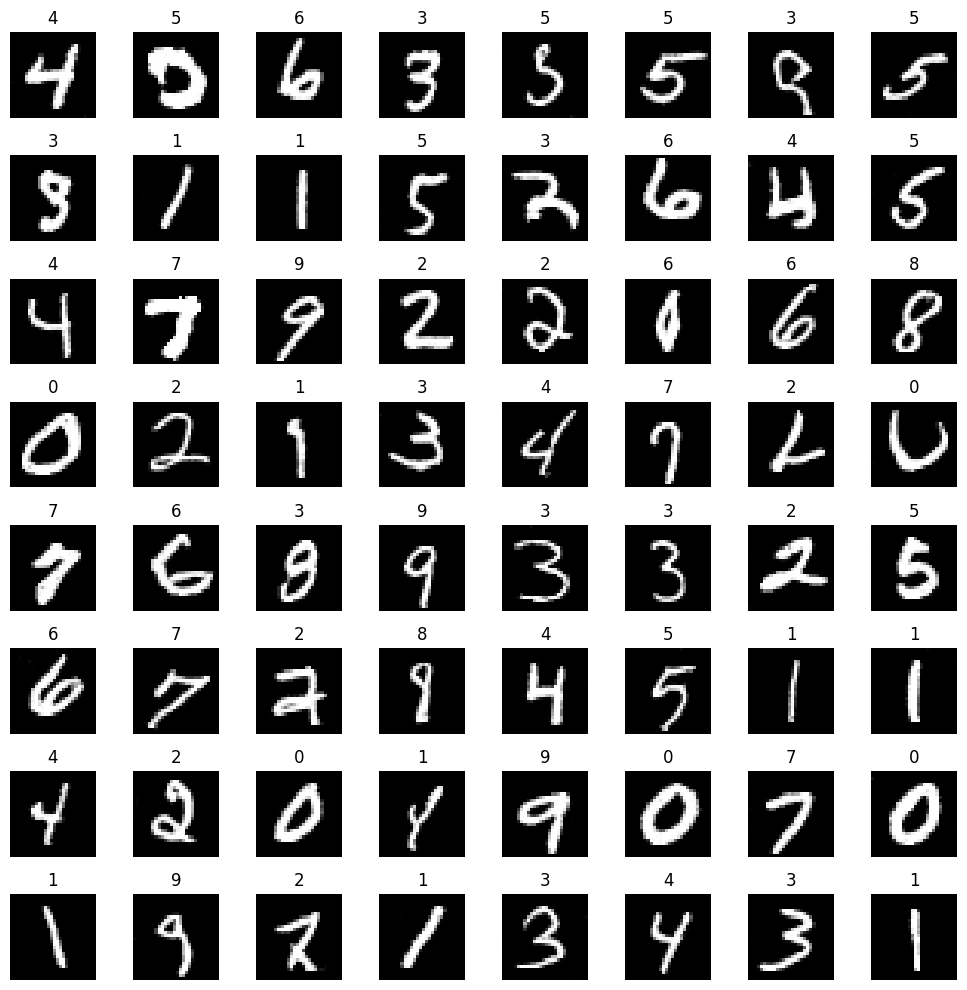

In [189]:
with torch.no_grad():
    z = torch.randn(64, 100, 1, 1, device=device)
    fake = netG(z)     # (64, 1, 28, 28)

print("fake shape from netG:", fake.shape)

with torch.no_grad():
    logits = clf(fake)
    preds = logits.argmax(dim=1)

print("Predicted digits:", preds.cpu().numpy())

probs = torch.softmax(logits, dim=1)
print("Probabilities for first 5 GAN digits:\n", probs[:5].cpu().numpy())

import matplotlib.pyplot as plt

plt.figure(figsize=(10,10))
for i in range(64):
    plt.subplot(8,8,i+1)
    plt.imshow(fake[i][0].cpu(), cmap='gray')
    plt.title(int(preds[i]))
    plt.axis("off")

plt.tight_layout()
plt.show()




=== PRE-UNLEARNING DISTRIBUTION ===
0: 875 (8.75%)
1: 1015 (10.15%)
2: 886 (8.86%)
3: 1442 (14.42%)
4: 1079 (10.79%)
5: 955 (9.55%)
6: 966 (9.66%)
7: 1161 (11.61%)
8: 730 (7.30%)
9: 875 (8.75%)


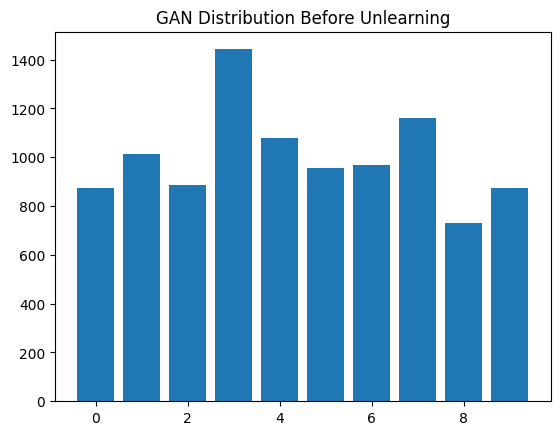

=== Starting UNLEARNING (FORGET DIGIT 0) ===

[E1 S0] Debug
  forget_conf mean: 0.08348660171031952
  forget_penalty: 0.008348660543560982
  gan_loss: 0.6837449669837952

[E1 S100] Debug
  forget_conf mean: 0.0024754530750215054
  forget_penalty: 0.00024754530750215054
  gan_loss: 0.6931453943252563

[E1 S200] Debug
  forget_conf mean: 0.000148010381963104
  forget_penalty: 1.4801038560108282e-05
  gan_loss: 0.6931455731391907

[E1 S300] Debug
  forget_conf mean: 0.00015451302169822156
  forget_penalty: 1.5451301806024276e-05
  gan_loss: 0.6931459903717041

[E1 S400] Debug
  forget_conf mean: 4.6983594074845314e-05
  forget_penalty: 4.698359589383472e-06
  gan_loss: 0.6931465864181519
[Epoch 1/50] 0 = 0.02%


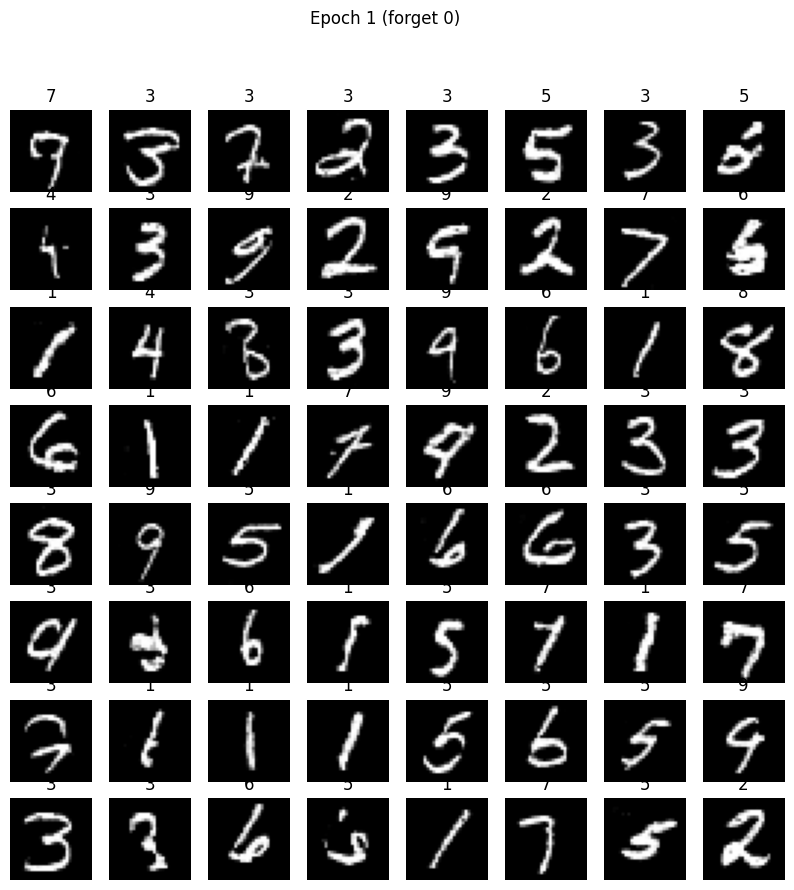


[E2 S0] Debug
  forget_conf mean: 6.585537630598992e-05
  forget_penalty: 6.585537903447403e-06
  gan_loss: 0.6931470036506653

[E2 S100] Debug
  forget_conf mean: 9.177836182061583e-05
  forget_penalty: 9.177836545859464e-06
  gan_loss: 0.693146824836731

[E2 S200] Debug
  forget_conf mean: 1.5294659533537924e-05
  forget_penalty: 1.52946597609116e-06
  gan_loss: 0.693146824836731

[E2 S300] Debug
  forget_conf mean: 6.30949143669568e-05
  forget_penalty: 6.3094917095440906e-06
  gan_loss: 0.6931469440460205

[E2 S400] Debug
  forget_conf mean: 1.124637492466718e-05
  forget_penalty: 1.124637492466718e-06
  gan_loss: 0.6931466460227966
[Epoch 2/50] 0 = 0.00%


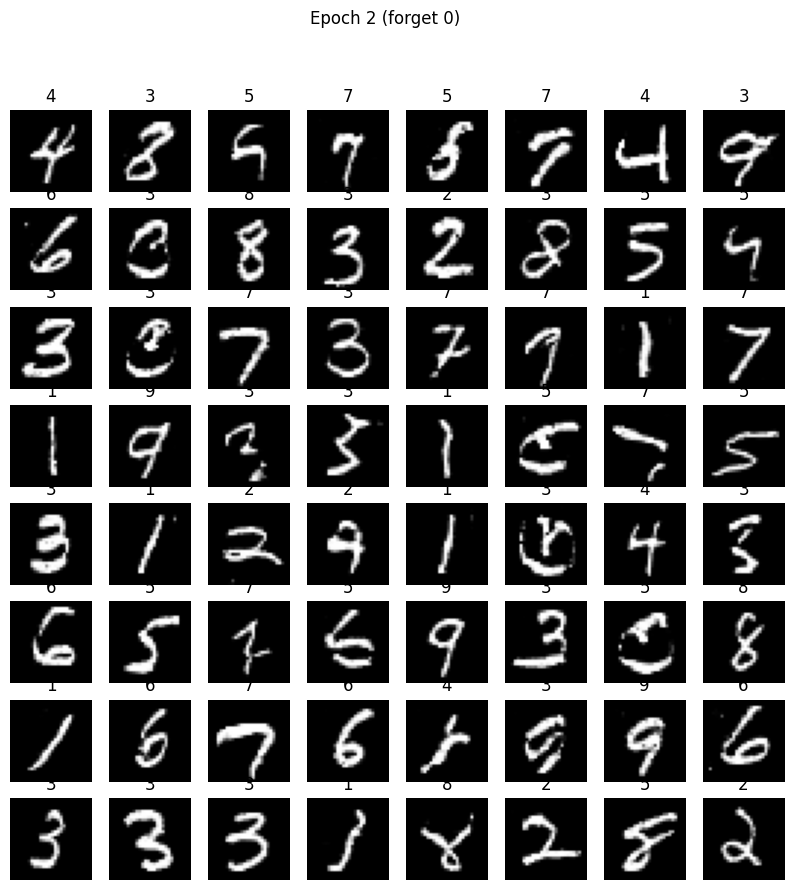


[E3 S0] Debug
  forget_conf mean: 9.341464647150133e-06
  forget_penalty: 9.341464988210646e-07
  gan_loss: 0.6931469440460205

[E3 S100] Debug
  forget_conf mean: 3.138208921882324e-05
  forget_penalty: 3.138208967357059e-06
  gan_loss: 0.6931464672088623

[E3 S200] Debug
  forget_conf mean: 6.904414931341307e-06
  forget_penalty: 6.90441481765447e-07
  gan_loss: 0.6931470036506653

[E3 S300] Debug
  forget_conf mean: 7.722323971393052e-06
  forget_penalty: 7.722323971393052e-07
  gan_loss: 0.6931470036506653

[E3 S400] Debug
  forget_conf mean: 1.1625934348558076e-05
  forget_penalty: 1.1625934348558076e-06
  gan_loss: 0.6931468844413757
[Epoch 3/50] 0 = 0.00%


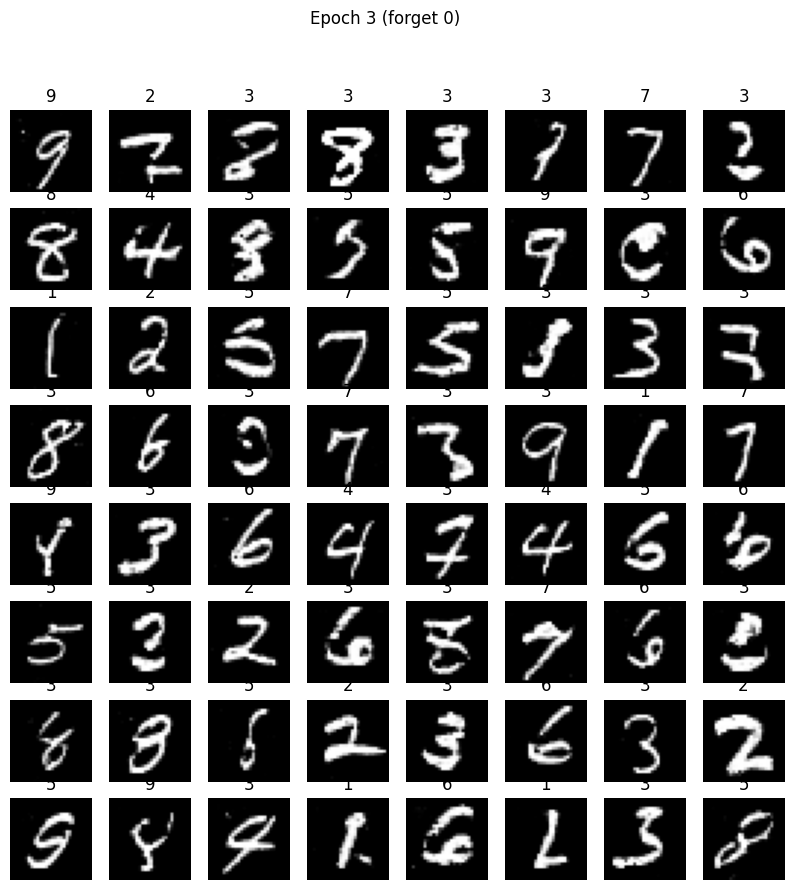


[E4 S0] Debug
  forget_conf mean: 7.00501868777792e-06
  forget_penalty: 7.005018574091082e-07
  gan_loss: 0.6931470036506653

[E4 S100] Debug
  forget_conf mean: 1.1406189514673315e-05
  forget_penalty: 1.1406190196794341e-06
  gan_loss: 0.6931470632553101

[E4 S200] Debug
  forget_conf mean: 5.012326255382504e-06
  forget_penalty: 5.01232648275618e-07
  gan_loss: 0.6931470632553101

[E4 S300] Debug
  forget_conf mean: 2.6040081138489768e-05
  forget_penalty: 2.604008159323712e-06
  gan_loss: 0.6931471824645996

[E4 S400] Debug
  forget_conf mean: 6.568953722307924e-06
  forget_penalty: 6.5689539496816e-07
  gan_loss: 0.6931471824645996
[Epoch 4/50] 0 = 0.00%


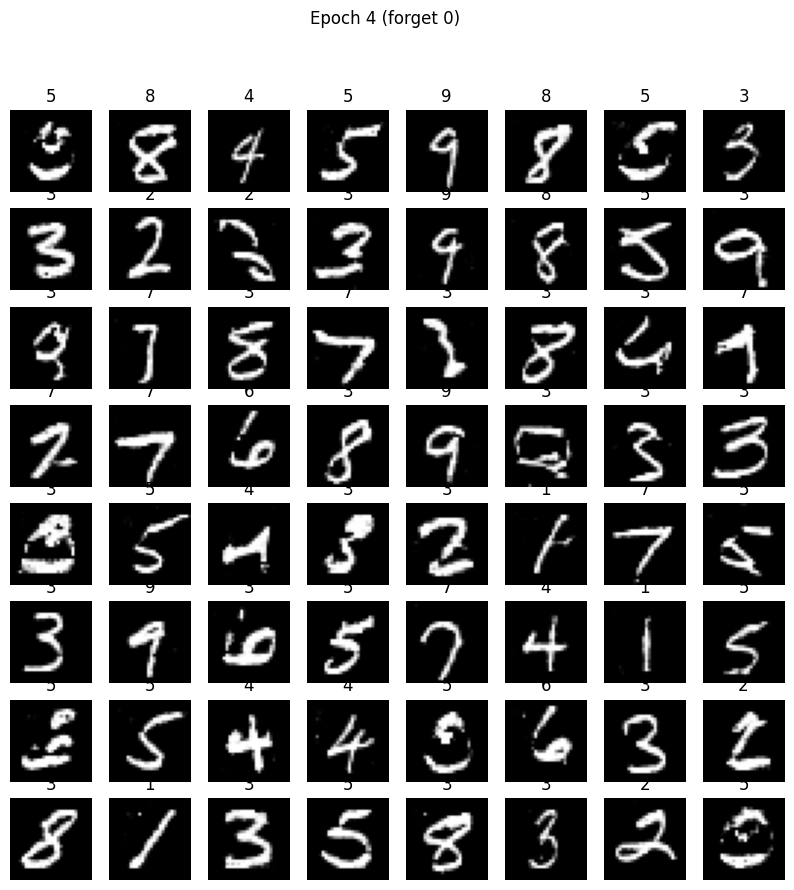


[E5 S0] Debug
  forget_conf mean: 5.129866622155532e-06
  forget_penalty: 5.12986673584237e-07
  gan_loss: 0.6931471228599548

[E5 S100] Debug
  forget_conf mean: 9.131625120062381e-06
  forget_penalty: 9.131625233749219e-07
  gan_loss: 0.6931471824645996

[E5 S200] Debug
  forget_conf mean: 2.8575245778483804e-06
  forget_penalty: 2.8575246346917993e-07
  gan_loss: 0.6931471824645996

[E5 S300] Debug
  forget_conf mean: 1.8601636838866398e-05
  forget_penalty: 1.8601637066240073e-06
  gan_loss: 0.6931471228599548

[E5 S400] Debug
  forget_conf mean: 3.81468180421507e-06
  forget_penalty: 3.8146819747453264e-07
  gan_loss: 0.6931471824645996
[Epoch 5/50] 0 = 0.00%


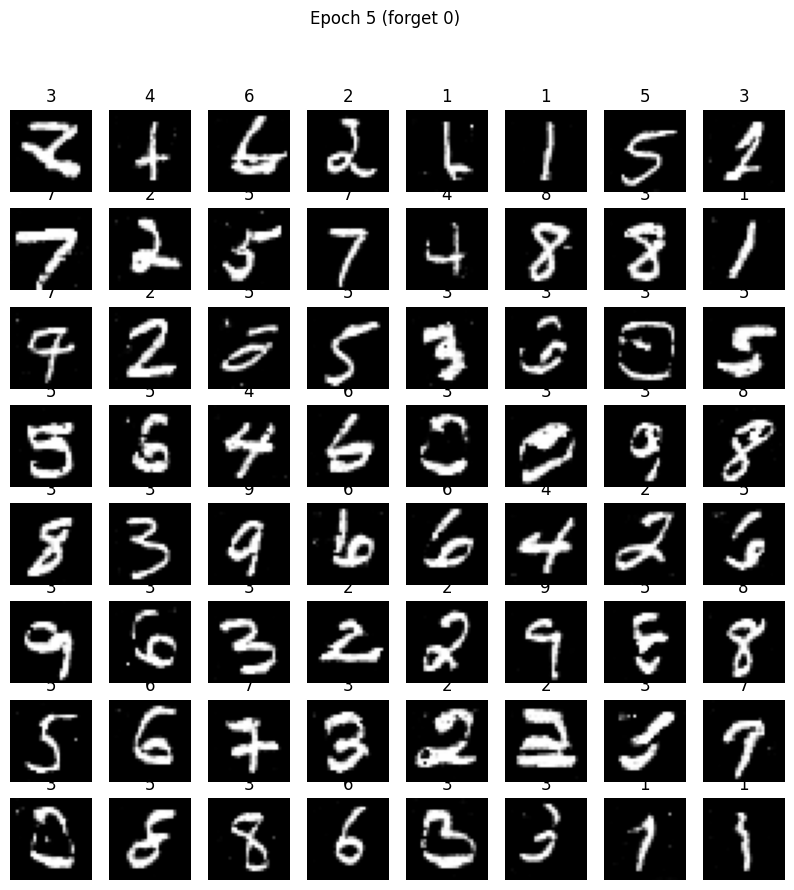


[E6 S0] Debug
  forget_conf mean: 1.2839497003369615e-06
  forget_penalty: 1.283949728758671e-07
  gan_loss: 0.6931470632553101


KeyboardInterrupt: 

In [190]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np

device = "cuda"

def to28(x):
    return F.interpolate(x, size=(28,28),
                         mode="bilinear",
                         align_corners=False)

clf.eval()
netG.eval()

N = 10000
batch = 256
all_preds = []

with torch.no_grad():
    for _ in range(N // batch):
        z = torch.randn(batch, 100, 1, 1, device=device)
        fake = netG(z)
        fake28 = to28(fake)
        logits = clf(fake28)
        preds = logits.argmax(1)
        all_preds.extend(preds.cpu().numpy())

all_preds = np.array(all_preds)
digit_counts = {d: int((all_preds == d).sum()) for d in range(10)}

print("=== PRE-UNLEARNING DISTRIBUTION ===")
for d in range(10):
    print(f"{d}: {digit_counts[d]} ({digit_counts[d]/N*100:.2f}%)")

plt.bar(digit_counts.keys(), digit_counts.values())
plt.title("GAN Distribution Before Unlearning")
plt.show()

forget_digit = 0
epochs = 50
batch_size = 128
nz = 100
λ = 0.1

optG = torch.optim.Adam(netG.parameters(), lr=2e-4, betas=(0.5, 0.999))
optD = torch.optim.Adam(netD.parameters(), lr=2e-4, betas=(0.5, 0.999))
criterion = nn.BCEWithLogitsLoss()

forget_percentages = []

print(f"forget digit {forget_digit}) =")

for epoch in range(epochs):
    for step in range(500):

        netD.zero_grad()

        real_imgs, _ = next(iter(train_loader))
        real_imgs = real_imgs.to(device)
        D_real = netD(real_imgs).view(-1)
        loss_D_real = criterion(D_real, torch.ones_like(D_real))

        z = torch.randn(batch_size, nz, 1, 1, device=device)
        fake = netG(z).detach()
        D_fake = netD(fake).view(-1)
        loss_D_fake = criterion(D_fake, torch.zeros_like(D_fake))

        loss_D = loss_D_real + loss_D_fake
        loss_D.backward()
        optD.step()

        netG.zero_grad()

        z = torch.randn(batch_size, nz, 1, 1, device=device)
        fake = netG(z)

        D_fake_new = netD(fake).view(-1)
        gan_loss = criterion(D_fake_new, torch.ones_like(D_fake_new))

        fake28 = to28(fake)

        logits = clf(fake28)
        soft = torch.softmax(logits, dim=1)
        forget_conf = soft[:, forget_digit]

        forget_penalty = λ * forget_conf.mean()
        loss_G = gan_loss + forget_penalty

        if step % 100 == 0:
            print(f"\n[E{epoch+1} S{step}] Debug")
            print("forget_conf mean:", forget_conf.mean().item())
            print("forget_penalty:", forget_penalty.item())
            print("gan_loss:", gan_loss.item())

        loss_G.backward()
        optG.step()

    with torch.no_grad():
        z_test = torch.randn(5000, nz, 1, 1, device=device)
        fake_test = netG(z_test)
        fake_test28 = to28(fake_test)
        preds = clf(fake_test28).argmax(1)
        ratio = (preds == forget_digit).float().mean().item()

    forget_percentages.append(ratio)
    print(f"[Epoch {epoch+1}/{epochs}] {forget_digit} = {ratio*100:.2f}%")

    with torch.no_grad():
        z_vis = torch.randn(64, nz, 1, 1, device=device)
        fake_vis = netG(z_vis)
        fake_vis28 = to28(fake_vis)
        preds_vis = clf(fake_vis28).argmax(1).cpu().numpy()

    plt.figure(figsize=(10,10))
    for i in range(64):
        plt.subplot(8,8,i+1)
        plt.imshow(fake_vis28[i][0].cpu(), cmap="gray")
        plt.title(str(preds_vis[i]))
        plt.axis("off")
    plt.suptitle(f"Epoch {epoch+1} (forget {forget_digit})")
    plt.show()

plt.plot(range(1, epochs+1), [p*100 for p in forget_percentages], marker='o')
plt.title(f"Percent of Digit {forget_digit} Generated")
plt.xlabel("Epoch")
plt.ylabel("Percentage")
plt.grid(True)
plt.show()
